### *Importando as bibliotecas necessárias*

In [1]:
# importando as bibliotecas necessárias
import pandas as pd
import seaborn as sns
import numpy as np
from scipy.stats import shapiro
from scipy.stats import zscore
from scipy.stats.mstats import winsorize
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import missingno as msno
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder


### *Carregando a base de dados*

In [2]:
url = "https://github.com/Taciana3090/PSI3/raw/Taciana3090/master/data/Life%20Expectancy%20Data.csv"
df = pd.read_csv(url)

# verificando se o conjunto de dados foi carregado corretamente
df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


### *Padronização das colunas*

In [3]:
orig_cols = list(df.columns)
new_cols = []
for col in orig_cols:
    new_cols.append(col.strip().replace('  ', ' ').replace(' ', '_').lower())
df.columns = new_cols

# Renomeando a coluna 'thinness_1-19_years' para 'thinness_10-19_years'
df.rename(columns={'thinness_1-19_years': 'thinness_10-19_years'}, inplace=True)


### *Explorando a Base de Dados: Primeiras Impressões*

In [4]:
print('------ Base de dados ------')
print(f'Números de linhas: {df.shape[0]}')
print(f'Números de colunas: {df.shape[1]}')

df.head()

------ Base de dados ------
Números de linhas: 2938
Números de colunas: 22


,country,year,status,life_expectancy,adult_mortality,infant_deaths,alcohol,percentage_expenditure,hepatitis_b,measles,...,polio,total_expenditure,diphtheria,hiv/aids,gdp,population,thinness_10-19_years,thinness_5-9_years,income_composition_of_resources,schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [5]:
# verificando as informações básicas da base de dados
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   country                          2938 non-null   object 
 1   year                             2938 non-null   int64  
 2   status                           2938 non-null   object 
 3   life_expectancy                  2928 non-null   float64
 4   adult_mortality                  2928 non-null   float64
 5   infant_deaths                    2938 non-null   int64  
 6   alcohol                          2744 non-null   float64
 7   percentage_expenditure           2938 non-null   float64
 8   hepatitis_b                      2385 non-null   float64
 9   measles                          2938 non-null   int64  
 10  bmi                              2904 non-null   float64
 11  under-five_deaths                2938 non-null   int64  
 12  polio               

A base de dados tem tem 22 colunas e 2938. As colunas incluem informações sobre a expectativa de vida, mortalidade, economia, social, população, PIB, consumo de álcool, tabagismo, dieta, exercício físico, etc.
Os tipos de dados são variados (float64, int64 e object). 

In [6]:
# soma dos dados faltantes por coluna com descrição
a = list(df.columns)
b = []
for i in a:
    c = df[i].isnull().sum()
    b.append(c)
null_df = pd.DataFrame({'Nome da coluna': a, 'N° de valores ausentes': b})
null_df['Porcentagem ausente (%)'] = round((null_df['N° de valores ausentes'] / len(df)) * 100, 2)
null_df = null_df.sort_values('N° de valores ausentes')
null_df['Porcentagem ausente (%)'] = null_df['Porcentagem ausente (%)'].astype(str) + '%'
null_df


,Nome da coluna,N° de valores ausentes,Porcentagem ausente (%)
0,country,0,0.0%
1,year,0,0.0%
2,status,0,0.0%
5,infant_deaths,0,0.0%
7,percentage_expenditure,0,0.0%
9,measles,0,0.0%
15,hiv/aids,0,0.0%
11,under-five_deaths,0,0.0%
3,life_expectancy,10,0.34%
4,adult_mortality,10,0.34%


*Vamos investigar mais a fundo os padrões dos valores ausentes em nossa base de dados. Isso nos ajudará a entender melhor a distribuição dos valores ausentes e, assim, tomar decisões mais acertadas sobre como lidar com eles.*

*Primeiro, analisaremos as colunas com os menores números de valores ausentes e verificaremos se existem padrões em relação a anos ou países específicos. Podemos começar identificando os anos e países onde temos valores ausentes nas colunas "life_expectancy" e "adult_mortality".*

In [7]:
# NaN para life_expectancy
df_life_expectancy = df[df['life_expectancy'].isnull()]
df_life_expectancy

,country,year,status,life_expectancy,adult_mortality,infant_deaths,alcohol,percentage_expenditure,hepatitis_b,measles,...,polio,total_expenditure,diphtheria,hiv/aids,gdp,population,thinness_10-19_years,thinness_5-9_years,income_composition_of_resources,schooling
624,Cook Islands,2013,Developing,NaN,NaN,0,0.01,0.000000,98.0,0,...,98.0,3.58,98.0,0.1,NaN,NaN,0.1,0.1,NaN,NaN
769,Dominica,2013,Developing,NaN,NaN,0,0.01,11.419555,96.0,0,...,96.0,5.58,96.0,0.1,722.756650,NaN,2.7,2.6,0.721,12.7
1650,Marshall Islands,2013,Developing,NaN,NaN,0,0.01,871.878317,8.0,0,...,79.0,17.24,79.0,0.1,3617.752354,NaN,0.1,0.1,NaN,0.0
1715,Monaco,2013,Developing,NaN,NaN,0,0.01,0.000000,99.0,0,...,99.0,4.30,99.0,0.1,NaN,NaN,NaN,NaN,NaN,NaN
1812,Nauru,2013,Developing,NaN,NaN,0,0.01,15.606596,87.0,0,...,87.0,4.65,87.0,0.1,136.183210,NaN,0.1,0.1,NaN,9.6
1909,Niue,2013,Developing,NaN,NaN,0,0.01,0.000000,99.0,0,...,99.0,7.20,99.0,0.1,NaN,NaN,0.1,0.1,NaN,NaN
1958,Palau,2013,Developing,NaN,NaN,0,NaN,344.690631,99.0,0,...,99.0,9.27,99.0,0.1,1932.122370,292.0,0.1,0.1,0.779,14.2
2167,Saint Kitts and Nevis,2013,Developing,NaN,NaN,0,8.54,0.000000,97.0,0,...,96.0,6.14,96.0,0.1,NaN,NaN,3.7,3.6,0.749,13.4
2216,San Marino,2013,Developing,NaN,NaN,0,0.01,0.000000,69.0,0,...,69.0,6.50,69.0,0.1,NaN,NaN,NaN,NaN,NaN,15.1
2713,Tuvalu,2013,Developing,NaN,NaN,0,0.01,78.281203,9.0,0,...,9.0,16.61,9.0,0.1,3542.135890,1819.0,0.2,0.1,NaN,0.0


*Considerando que os valores ausentes nas colunas "life_expectancy" e "adult_mortality" são os mesmos, eliminar as linhas com valores ausentes não seria a melhor abordagem, pois perderíamos informações importantes sobre a expectativa de vida.*

In [8]:
# NaN para polio
df_polio = df[df['polio'].isnull()]
df_polio

,country,year,status,life_expectancy,adult_mortality,infant_deaths,alcohol,percentage_expenditure,hepatitis_b,measles,...,polio,total_expenditure,diphtheria,hiv/aids,gdp,population,thinness_10-19_years,thinness_5-9_years,income_composition_of_resources,schooling
1742,Montenegro,2005,Developing,73.6,133.0,0,NaN,527.307672,NaN,0,...,NaN,8.46,NaN,0.1,3674.617924,614261.0,2.3,2.3,0.746,12.8
1743,Montenegro,2004,Developing,73.5,134.0,0,0.01,57.121901,NaN,0,...,NaN,8.45,NaN,0.1,338.199535,613353.0,2.3,2.4,0.740,12.6
1744,Montenegro,2003,Developing,73.5,134.0,0,0.01,495.078296,NaN,0,...,NaN,8.91,NaN,0.1,2789.173500,612267.0,2.4,2.4,0.000,0.0
1745,Montenegro,2002,Developing,73.4,136.0,0,0.01,36.480240,NaN,0,...,NaN,8.33,NaN,0.1,216.243274,69828.0,2.5,2.5,0.000,0.0
1746,Montenegro,2001,Developing,73.3,136.0,0,0.01,33.669814,NaN,0,...,NaN,8.23,NaN,0.1,199.583957,67389.0,2.5,2.6,0.000,0.0
1747,Montenegro,2000,Developing,73.0,144.0,0,0.01,274.547260,NaN,0,...,NaN,7.32,NaN,0.1,1627.428930,6495.0,2.6,2.7,0.000,0.0
2414,South Sudan,2010,Developing,55.0,359.0,27,NaN,0.000000,NaN,0,...,NaN,NaN,NaN,4.0,1562.239346,167192.0,NaN,NaN,0.000,0.0
2415,South Sudan,2009,Developing,54.3,369.0,27,NaN,0.000000,NaN,0,...,NaN,NaN,NaN,4.2,1264.789980,967667.0,NaN,NaN,0.000,0.0
2416,South Sudan,2008,Developing,53.6,377.0,27,NaN,0.000000,NaN,0,...,NaN,NaN,NaN,4.2,1678.711862,9263136.0,NaN,NaN,0.000,0.0
2417,South Sudan,2007,Developing,53.1,381.0,27,NaN,0.000000,NaN,0,...,NaN,NaN,NaN,4.2,NaN,88568.0,NaN,NaN,0.000,0.0


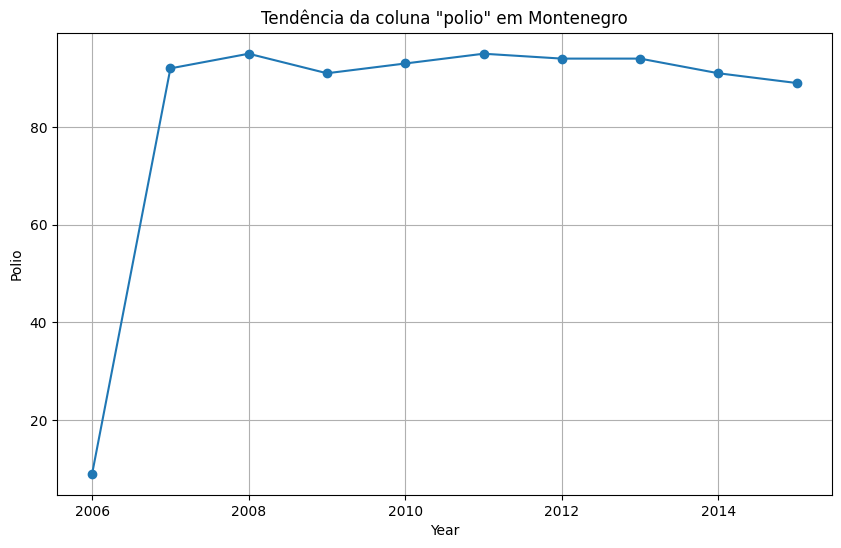

In [9]:
# Filtrar o DataFrame para o país "Montenegro"
country_name = 'Montenegro'
df_country = df[df['country'] == country_name]

# Plotar gráfico de linha para a coluna "polio"
plt.figure(figsize=(10, 6))
plt.plot(df_country['year'], df_country['polio'], marker='o', linestyle='-')
plt.xlabel('Year')
plt.ylabel('Polio')
plt.title(f'Tendência da coluna "polio" em {country_name}')
plt.grid(True)
plt.show()

In [10]:
# NaN para population
df_population = df[df['population'].isnull()]
df_population

,country,year,status,life_expectancy,adult_mortality,infant_deaths,alcohol,percentage_expenditure,hepatitis_b,measles,...,polio,total_expenditure,diphtheria,hiv/aids,gdp,population,thinness_10-19_years,thinness_5-9_years,income_composition_of_resources,schooling
64,Antigua and Barbuda,2015,Developing,76.4,13.0,0,NaN,0.000000,99.0,0,...,86.0,NaN,99.0,0.2,13566.95410,NaN,3.3,3.3,0.784,13.9
65,Antigua and Barbuda,2014,Developing,76.2,131.0,0,8.56,2422.999774,99.0,0,...,96.0,5.54,99.0,0.2,12888.29667,NaN,3.3,3.3,0.782,13.9
66,Antigua and Barbuda,2013,Developing,76.1,133.0,0,8.58,1991.430372,99.0,0,...,98.0,5.33,99.0,0.2,12224.86416,NaN,3.3,3.3,0.781,13.9
67,Antigua and Barbuda,2012,Developing,75.9,134.0,0,8.18,2156.229842,98.0,0,...,97.0,5.39,98.0,0.2,12565.44197,NaN,3.3,3.3,0.778,13.8
68,Antigua and Barbuda,2011,Developing,75.7,136.0,0,7.84,1810.875316,99.0,0,...,99.0,5.65,99.0,0.1,11929.34991,NaN,3.3,3.3,0.782,14.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2901,Yemen,2004,Developing,62.2,247.0,42,0.06,0.000000,43.0,12708,...,72.0,4.90,72.0,0.1,NaN,NaN,13.9,13.9,0.464,8.4
2902,Yemen,2003,Developing,61.9,249.0,43,0.04,0.000000,38.0,8536,...,61.0,5.00,61.0,0.1,NaN,NaN,14.0,13.9,0.457,8.2
2903,Yemen,2002,Developing,61.5,25.0,45,0.07,0.000000,31.0,890,...,64.0,4.22,65.0,0.1,NaN,NaN,14.0,14.0,0.450,8.0
2904,Yemen,2001,Developing,61.1,251.0,46,0.08,0.000000,19.0,485,...,73.0,4.34,73.0,0.1,NaN,NaN,14.0,14.0,0.444,7.9


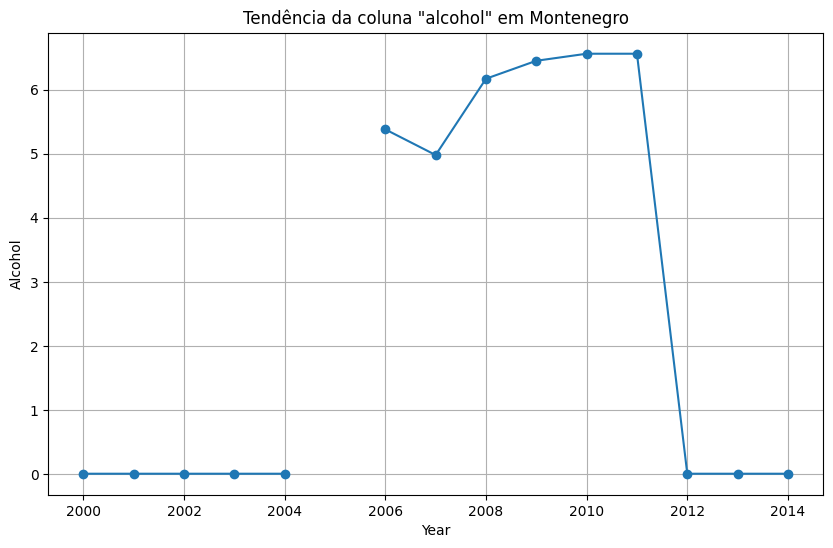

In [11]:
# Filtrar o DataFrame para o país "Montenegro"
country_name = 'Montenegro'
df_country = df[df['country'] == country_name]

# Plotar gráfico de linha para a coluna "alcohol"
plt.figure(figsize=(10, 6))
plt.plot(df_country['year'], df_country['alcohol'], marker='o', linestyle='-')
plt.xlabel('Year')
plt.ylabel('Alcohol')
plt.title(f'Tendência da coluna "alcohol" em {country_name}')
plt.grid(True)
plt.show()

<Axes: >

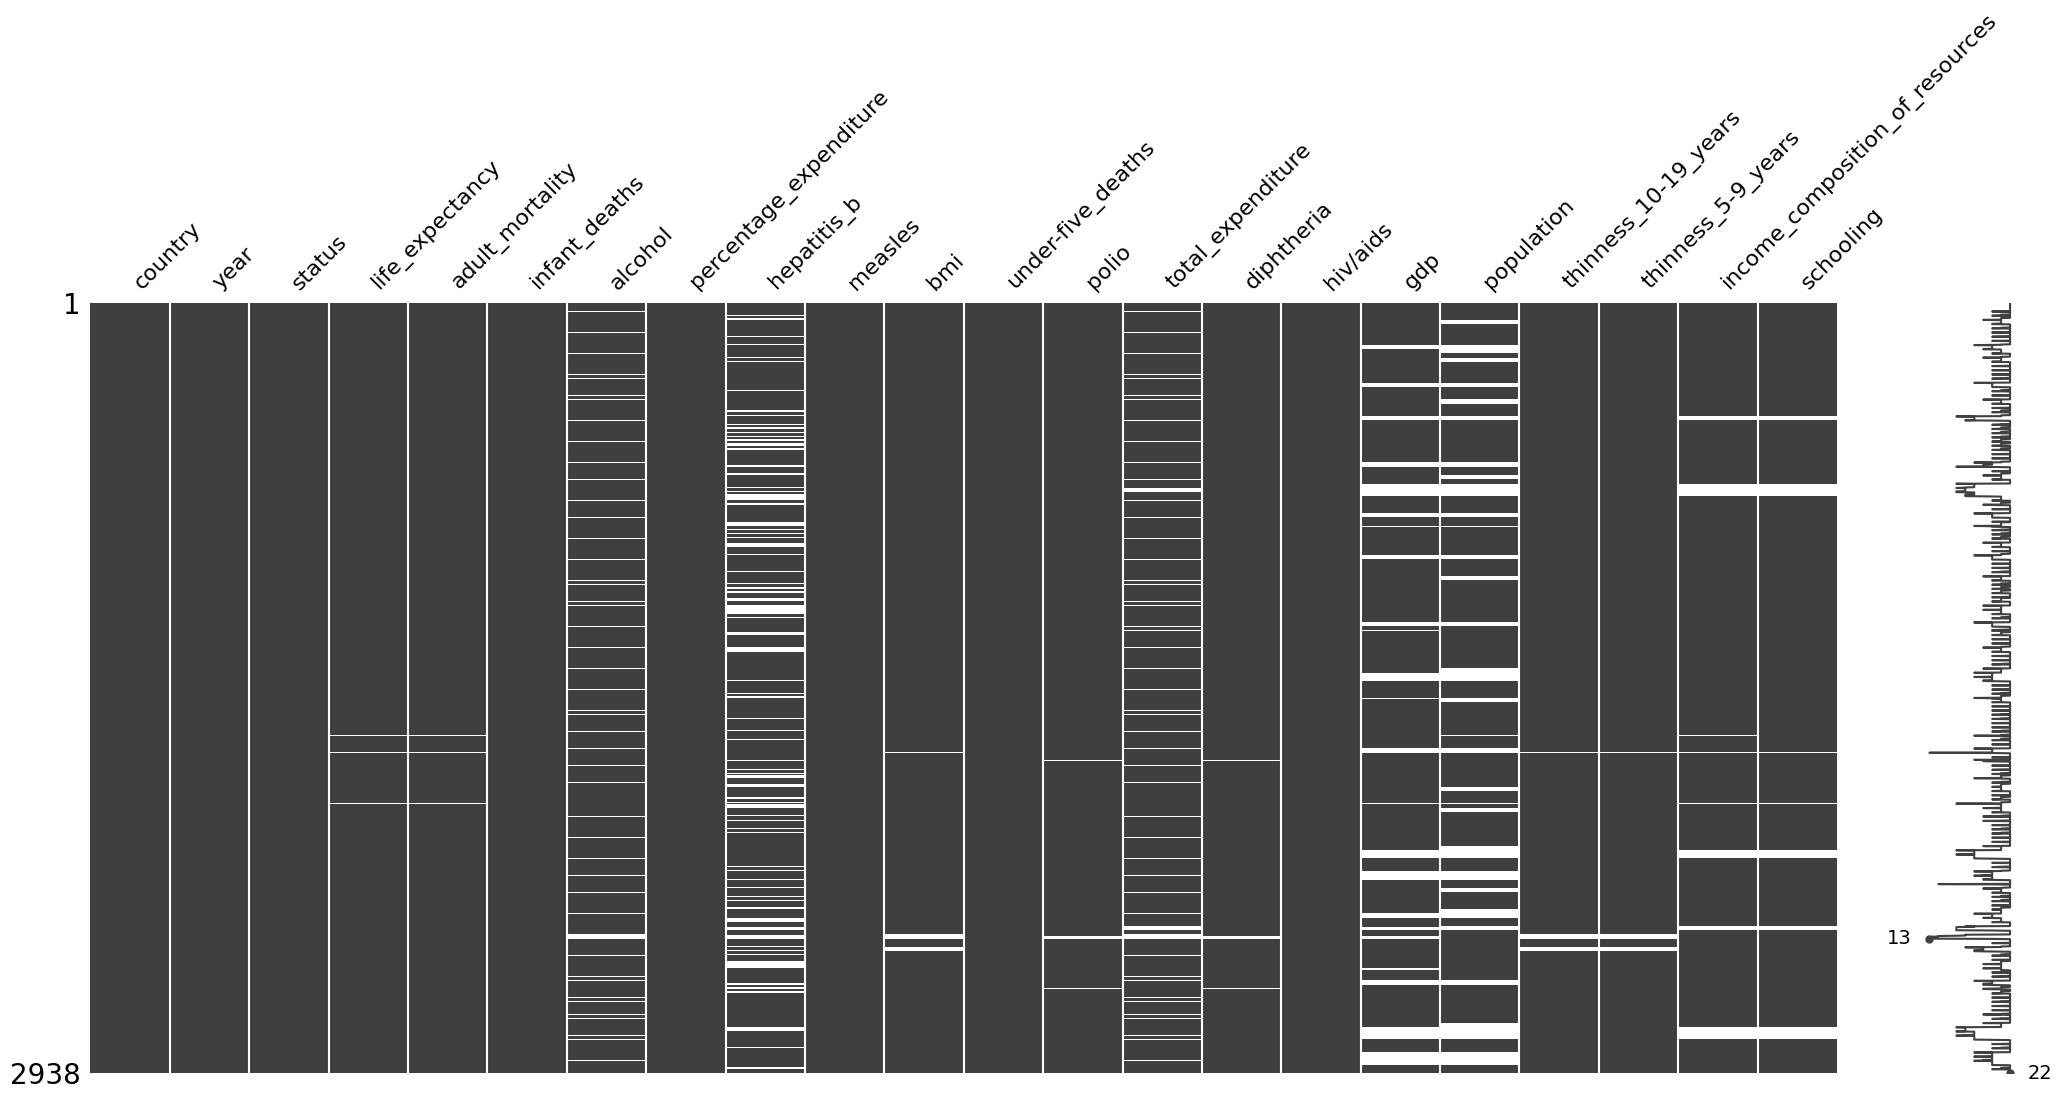

In [12]:
# matriz de dados ausentes
msno.matrix(df)

In [13]:
# exclui as colunas não numéricas
df_numeric = df.select_dtypes(include=[np.number])

# correlações entre 'life_expectancy' e todas as colunas numéricas
correlation_matrix = df_numeric.corr()
correlation_with_life_expectancy = correlation_matrix['life_expectancy'].sort_values(ascending=False)
for column, correlation in correlation_with_life_expectancy.items():
    print(f"Correlação entre 'life_expectancy' e '{column}': {correlation}")


Correlação entre 'life_expectancy' e 'life_expectancy': 1.0
Correlação entre 'life_expectancy' e 'schooling': 0.7519754627367001
Correlação entre 'life_expectancy' e 'income_composition_of_resources': 0.7247759785960587
Correlação entre 'life_expectancy' e 'bmi': 0.5676935475459853
Correlação entre 'life_expectancy' e 'diphtheria': 0.47949486434158606
Correlação entre 'life_expectancy' e 'polio': 0.46555580597719776
Correlação entre 'life_expectancy' e 'gdp': 0.4614551926207384
Correlação entre 'life_expectancy' e 'alcohol': 0.4048767611266021
Correlação entre 'life_expectancy' e 'percentage_expenditure': 0.38186350339004915
Correlação entre 'life_expectancy' e 'hepatitis_b': 0.25676194760492504
Correlação entre 'life_expectancy' e 'total_expenditure': 0.21808637369167103
Correlação entre 'life_expectancy' e 'year': 0.17003302485908775
Correlação entre 'life_expectancy' e 'population': -0.021538108386786287
Correlação entre 'life_expectancy' e 'measles': -0.15758580377505788
Correlação

*Podemos observar no quadro acima que os fatores relacionados à educação, desenvolvimento econômico e saúde pública parecem ter uma forte influência positiva na expectativa de vida, enquanto questões de saúde como o HIV/AIDS e a mortalidade em adultos estão associadas negativamente à longevidade.*

*É importante ressaltar que nem todas as variáveis apresentaram correlações significativas com a expectativa de vida. Por exemplo, 'population', 'measles' e 'infant_deaths' mostraram correlações próximas a zero, sugerindo que esses fatores não têm uma influência linear significativa na expectativa de vida*

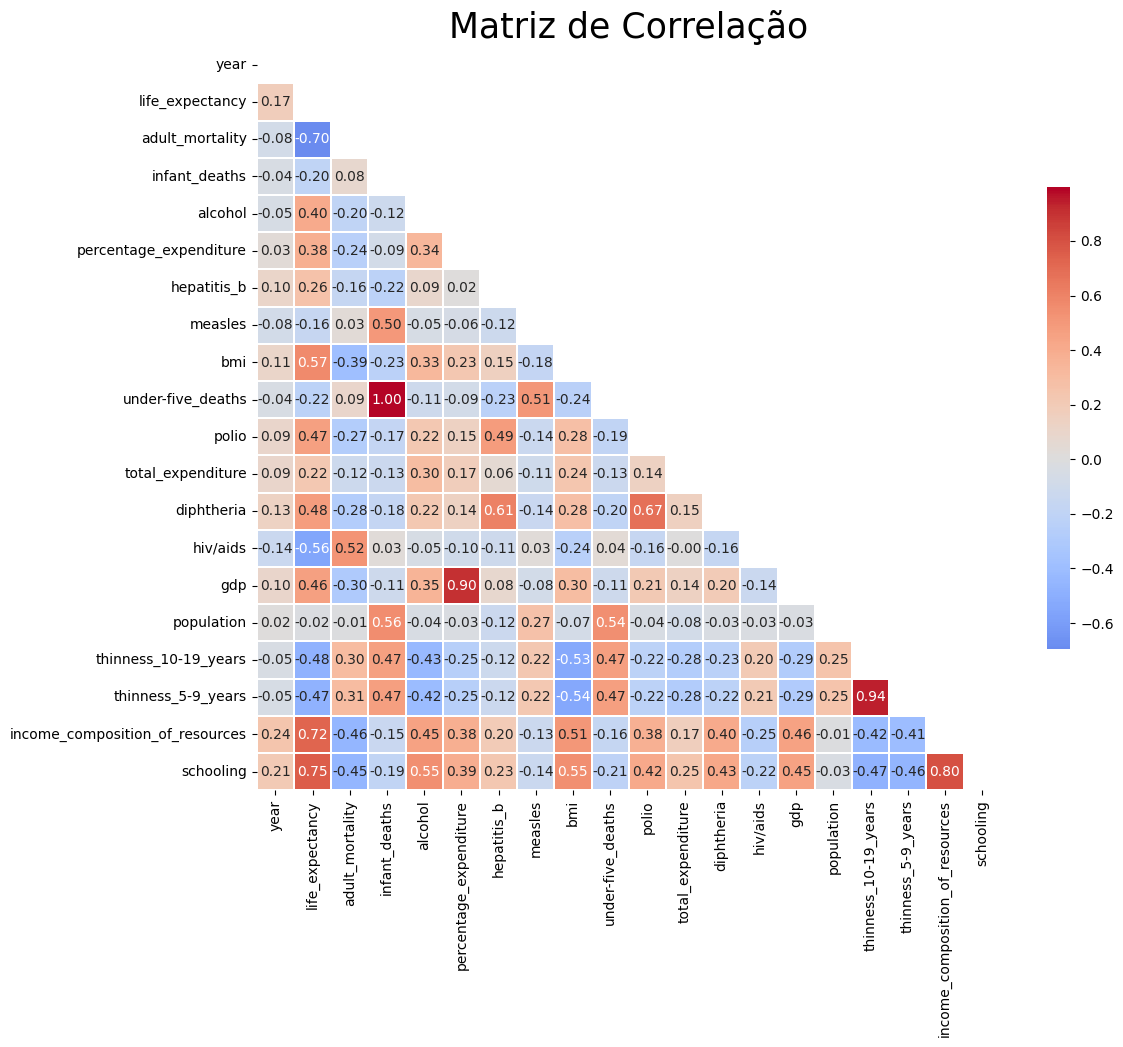

In [14]:
# apenas as colunas numéricas para a matriz de correlação
numeric_cols = df.select_dtypes(include=[np.number])
corr = numeric_cols.corr()

# cria uma máscara triangular superior para esconder a metade inferior da matriz (evita duplicações)
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(12, 10))

# matriz de correlação em um heatmap
heatmap_colors = "coolwarm"
sns.heatmap(corr,
            mask=mask,
            center=0,
            annot=True,
            fmt='.2f',
            cmap=heatmap_colors,
            square=True,
            linewidths=.2,
            cbar_kws={"shrink": .6})
plt.title('Matriz de Correlação', fontsize=25)
plt.show()


In [15]:
# Função para aplicar a interpolação linear
def interpolate_linear(column):
    return column.interpolate(limit_direction='both')

# Função para aplicar o KNN
def knn_impute(df, n_neighbors=5):
    imputer = KNNImputer(n_neighbors=n_neighbors)
    return pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

# Colunas para aplicar a interpolação linear
linear_cols = ['life_expectancy', 'adult_mortality', 'polio', 'diphtheria',
               'thinness_5-9_years', 'thinness_10-19_years', 'bmi',
               'schooling', 'income_composition_of_resources']

# Colunas para aplicar o KNN
knn_cols = ['alcohol', 'total_expenditure', 'gdp', 'hepatitis_b', 'population']

# Aplicar a interpolação linear nas colunas correspondentes
df[linear_cols] = df[linear_cols].apply(interpolate_linear)

# Aplicar o KNN nas colunas correspondentes
df_knn = knn_impute(df[knn_cols])
df[knn_cols] = df_knn

# Juntar as colunas do KNN com as colunas da interpolação linear
df_final = pd.concat([df.drop(columns=knn_cols), df_knn], axis=1)

print("Valores ausentes após as técnicas:")
print(df_final.isnull().sum())

Valores ausentes após as técnicas:
country                            0
year                               0
status                             0
life_expectancy                    0
adult_mortality                    0
infant_deaths                      0
percentage_expenditure             0
measles                            0
bmi                                0
under-five_deaths                  0
polio                              0
diphtheria                         0
hiv/aids                           0
thinness_10-19_years               0
thinness_5-9_years                 0
income_composition_of_resources    0
schooling                          0
alcohol                            0
total_expenditure                  0
gdp                                0
hepatitis_b                        0
population                         0
dtype: int64


In [16]:
# Calculando as métricas descritivas para as variáveis numéricas
desc_metrics = df_final.describe()

# Exibindo o resultado
print(desc_metrics)

              year  life_expectancy  adult_mortality  infant_deaths  \
count  2938.000000      2938.000000      2938.000000    2938.000000   
mean   2007.518720        69.214874       164.744554      30.303948   
std       4.613841         9.510819       124.226596     117.926501   
min    2000.000000        36.300000         1.000000       0.000000   
25%    2004.000000        63.100000        74.000000       0.000000   
50%    2008.000000        72.000000       144.000000       3.000000   
75%    2012.000000        75.600000       228.000000      22.000000   
max    2015.000000        89.000000       723.000000    1800.000000   

       percentage_expenditure        measles         bmi  under-five_deaths  \
count             2938.000000    2938.000000  2938.00000        2938.000000   
mean               738.251295    2419.592240    38.29869          42.035739   
std               1987.914858   11467.272489    19.99140         160.445548   
min                  0.000000       0.000000

In [17]:
# Selecionar apenas as colunas numéricas
numeric_cols = df_final.select_dtypes(include=[np.number])

# Calcular a assimetria e a curtose para todas as colunas numéricas
assimetria = numeric_cols.apply(pd.Series.skew)
curtose = numeric_cols.apply(pd.Series.kurtosis)

# Criar um DataFrame para visualizar os resultados
resultados = pd.DataFrame({'Assimetria': assimetria, 'Curtose': curtose})

print(resultados)



                                 Assimetria     Curtose
year                              -0.006409   -1.213722
life_expectancy                   -0.636290   -0.231168
adult_mortality                    1.172524    1.746856
infant_deaths                      9.786963  116.042756
percentage_expenditure             4.652051   26.573387
measles                            9.441332  114.859903
bmi                               -0.217215   -1.286784
under-five_deaths                  9.495065  109.752795
polio                             -2.087701    3.738123
diphtheria                        -2.062557    3.522924
hiv/aids                           5.396112   34.892008
thinness_10-19_years               1.677485    3.800683
thinness_5-9_years                 1.739586    4.142077
income_composition_of_resources   -1.167781    1.445488
schooling                         -0.616869    0.901798
alcohol                            0.601211   -0.708538
total_expenditure                  0.634242    1

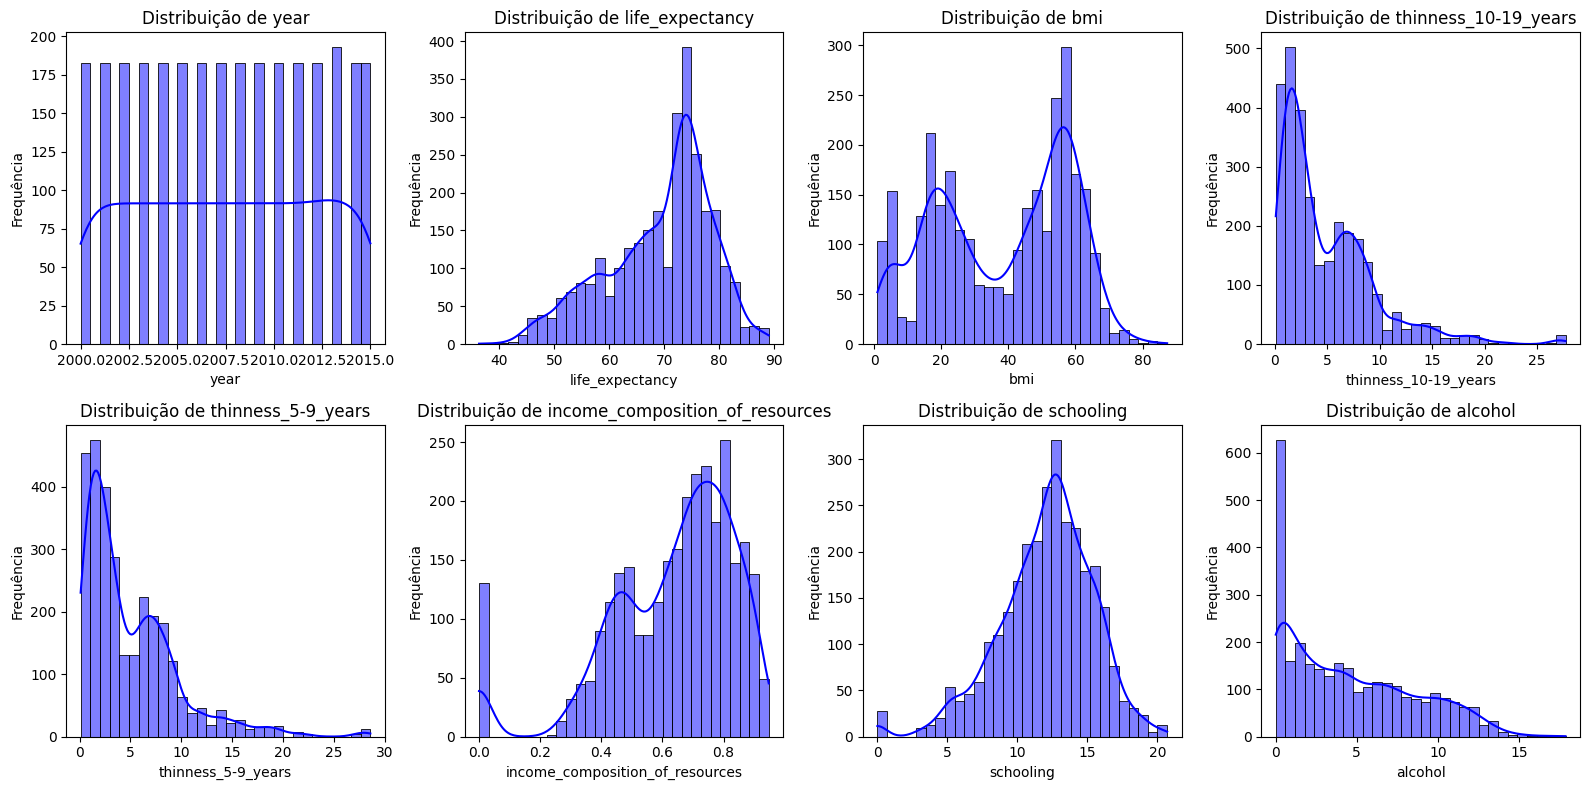

In [18]:
# Lista das colunas com distribuição normal
normal_cols = ['year', 'life_expectancy', 'bmi', 'thinness_10-19_years', 'thinness_5-9_years', 'income_composition_of_resources', 'schooling', 'alcohol']

# Plotagem dos histogramas para as colunas com distribuição normal
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16, 8))
for i, col in enumerate(normal_cols):
    row_idx = i // 4
    col_idx = i % 4
    sns.histplot(df_final[col], kde=True, color='blue', bins=30, ax=axes[row_idx, col_idx])
    axes[row_idx, col_idx].set_xlabel(col)
    axes[row_idx, col_idx].set_ylabel('Frequência')
    axes[row_idx, col_idx].set_title(f'Distribuição de {col}')
plt.tight_layout()
plt.show()


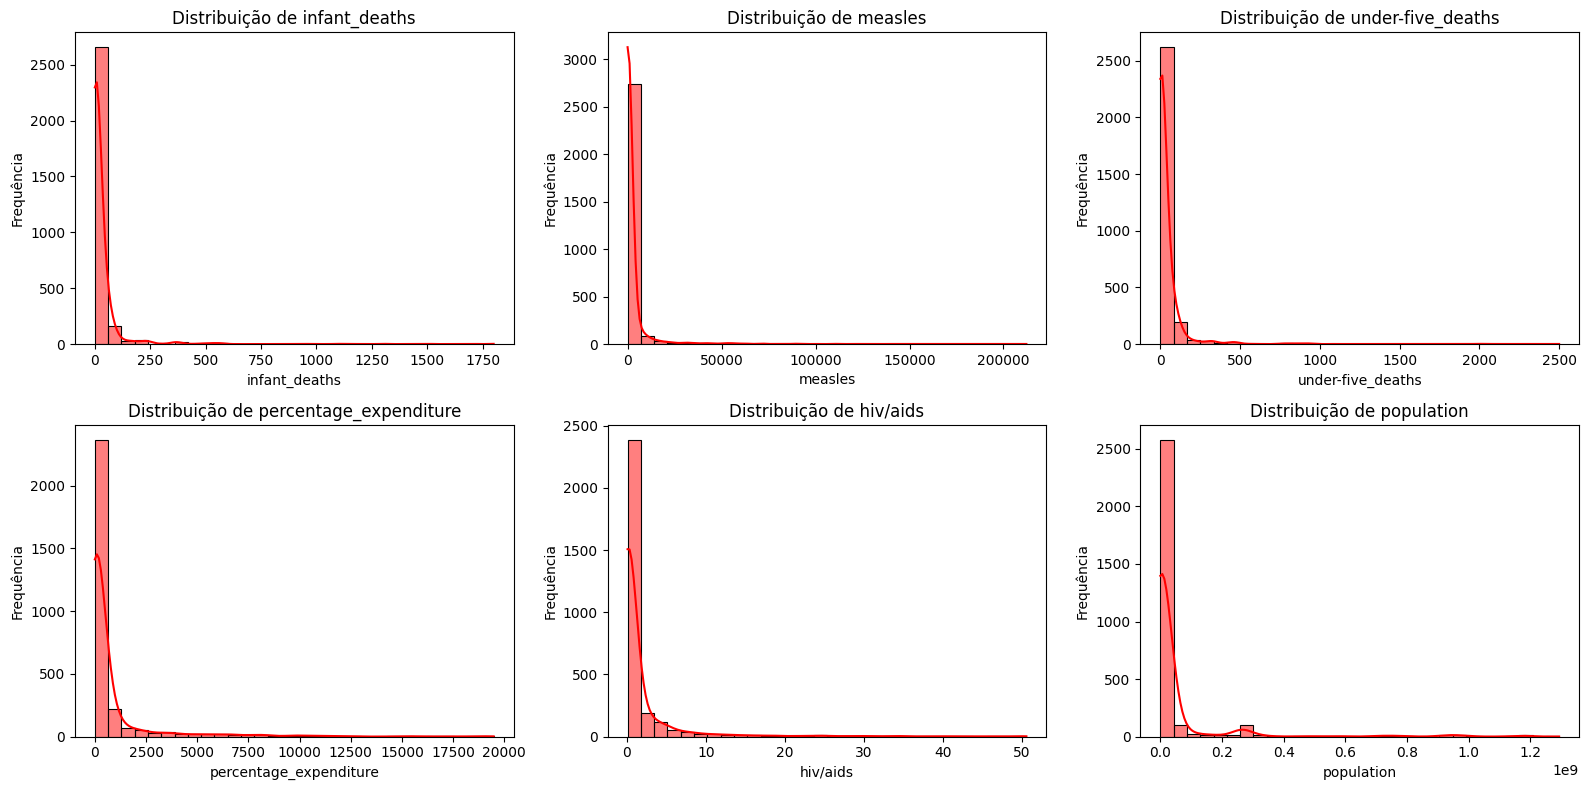

In [19]:
# Lista das colunas com distribuição não-normal
non_normal_cols = ['infant_deaths', 'measles', 'under-five_deaths', 'percentage_expenditure', 'hiv/aids', 'population']

# Plotagem dos histogramas para as colunas com distribuição não-normal
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 8))
for i, col in enumerate(non_normal_cols):
    row_idx = i // 3
    col_idx = i % 3
    sns.histplot(df_final[col], kde=True, color='red', bins=30, ax=axes[row_idx, col_idx])
    axes[row_idx, col_idx].set_xlabel(col)
    axes[row_idx, col_idx].set_ylabel('Frequência')
    axes[row_idx, col_idx].set_title(f'Distribuição de {col}')
plt.tight_layout()
plt.show()


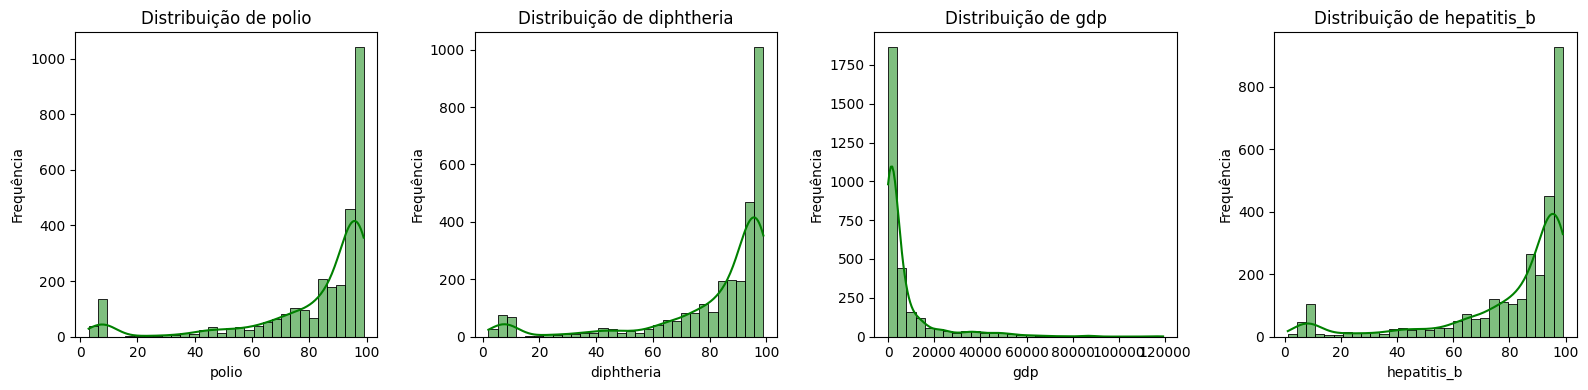

In [20]:
# Lista das colunas com distribuição platicúrtica
platykurtic_cols = ['polio', 'diphtheria', 'gdp', 'hepatitis_b']

# Plotagem dos histogramas para as colunas com distribuição platicúrtica
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4))
for i, col in enumerate(platykurtic_cols):
    sns.histplot(df[col], kde=True, color='green', bins=30, ax=axes[i])
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequência')
    axes[i].set_title(f'Distribuição de {col}')
plt.tight_layout()
plt.show()


In [21]:
# Criar um dicionário com as colunas e seus respectivos valores
col_dict = df_final.to_dict()

# Calcular o número de outliers e porcentagem para cada coluna
outliers_info = {}
for variable in col_dict.keys():
    values = pd.to_numeric(list(col_dict[variable].values()), errors='coerce')

    if len(values) > 0:
        q75, q25 = np.percentile(values, [75, 25])
        iqr = q75 - q25

        min_val = q25 - (iqr * 1.5)
        max_val = q75 + (iqr * 1.5)

        outliers = np.where((values > max_val) | (values < min_val))[0]
        num_outliers = len(outliers)
        percent_outliers = num_outliers * 100 / len(values)

        outliers_info[variable] = (num_outliers, percent_outliers)
    else:
        outliers_info[variable] = (0, 0.0)

# Exibir o resultado formatado
for variable, (num_outliers, percent_outliers) in outliers_info.items():
    print(f"Coluna '{variable}': {num_outliers} outliers ({percent_outliers:.2f}%)")


Coluna 'country': 0 outliers (0.00%)
Coluna 'year': 0 outliers (0.00%)
Coluna 'status': 0 outliers (0.00%)
Coluna 'life_expectancy': 12 outliers (0.41%)
Coluna 'adult_mortality': 82 outliers (2.79%)
Coluna 'infant_deaths': 315 outliers (10.72%)
Coluna 'percentage_expenditure': 389 outliers (13.24%)
Coluna 'measles': 542 outliers (18.45%)
Coluna 'bmi': 0 outliers (0.00%)
Coluna 'under-five_deaths': 394 outliers (13.41%)
Coluna 'polio': 282 outliers (9.60%)
Coluna 'diphtheria': 301 outliers (10.25%)
Coluna 'hiv/aids': 542 outliers (18.45%)
Coluna 'thinness_10-19_years': 89 outliers (3.03%)
Coluna 'thinness_5-9_years': 97 outliers (3.30%)
Coluna 'income_composition_of_resources': 130 outliers (4.42%)
Coluna 'schooling': 53 outliers (1.80%)
Coluna 'alcohol': 2 outliers (0.07%)
Coluna 'total_expenditure': 36 outliers (1.23%)
Coluna 'gdp': 369 outliers (12.56%)
Coluna 'hepatitis_b': 288 outliers (9.80%)
Coluna 'population': 449 outliers (15.28%)


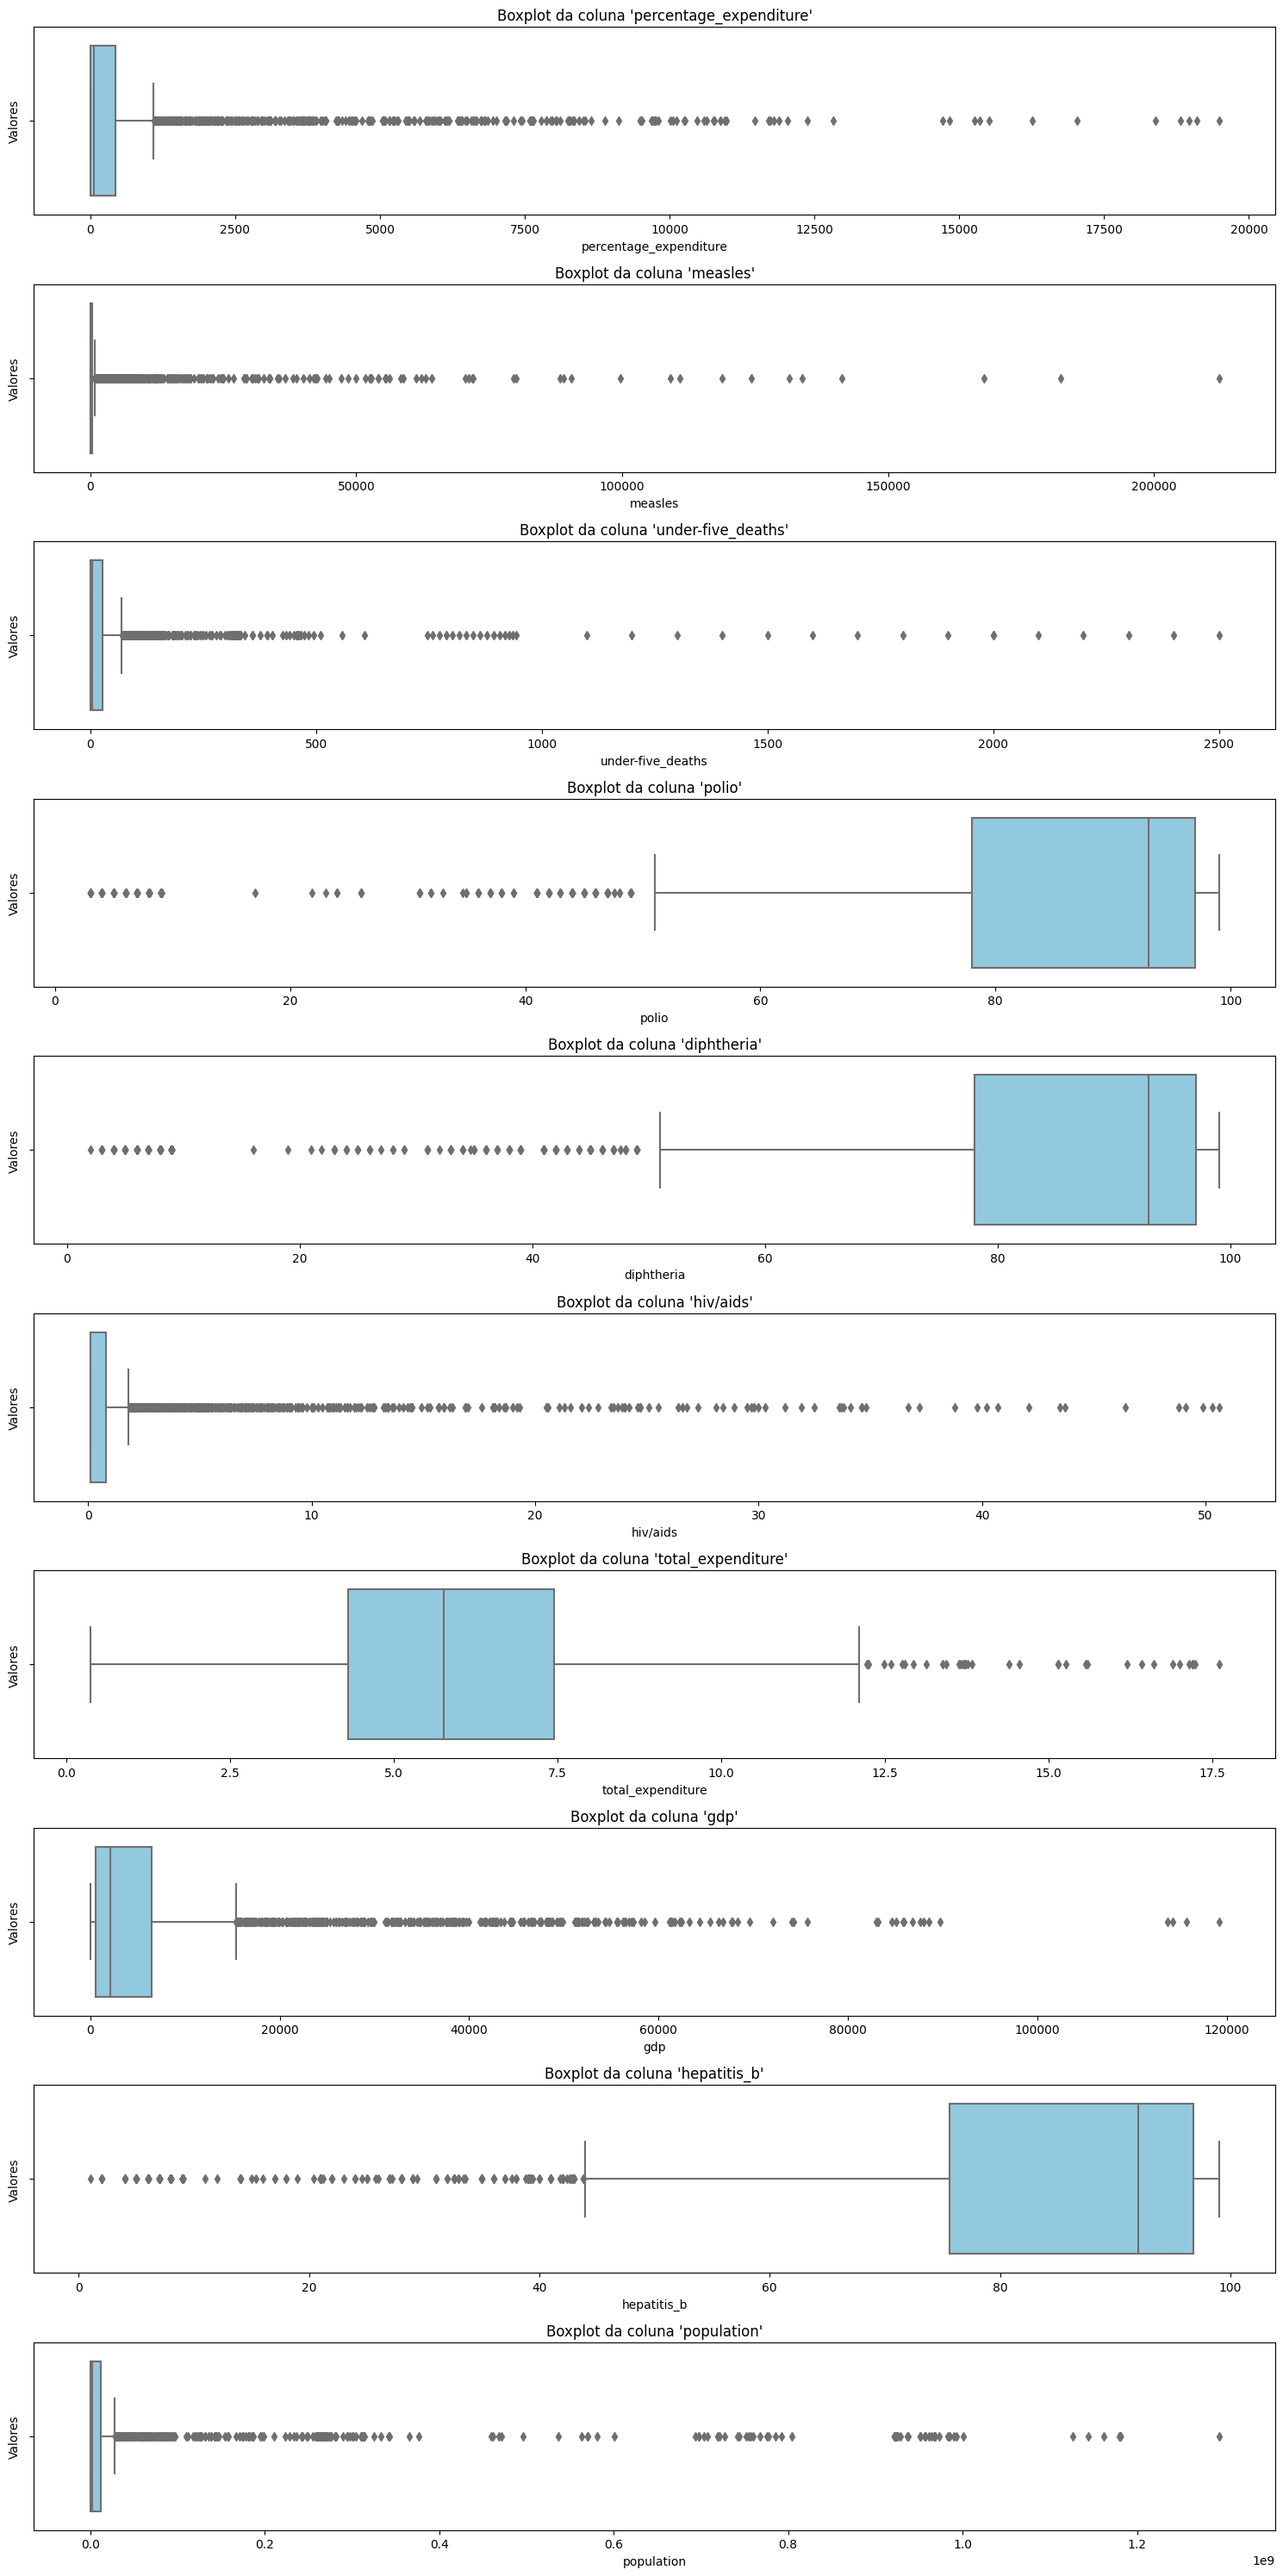

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

# Lista das colunas com distribuição não-normal ou platicúrtica
cols_with_outliers = ['percentage_expenditure', 'measles', 'under-five_deaths', 'polio', 'diphtheria', 'hiv/aids', 
                      'total_expenditure', 'gdp', 'hepatitis_b', 'population']

# Plotar boxplots para cada coluna
plt.figure(figsize=(15, 30))
for i, col in enumerate(cols_with_outliers):
    plt.subplot(len(cols_with_outliers), 1, i+1)
    sns.boxplot(x=df_final[col], color='skyblue')
    plt.title(f"Boxplot da coluna '{col}'")
    plt.ylabel("Valores")
plt.tight_layout()
plt.show()


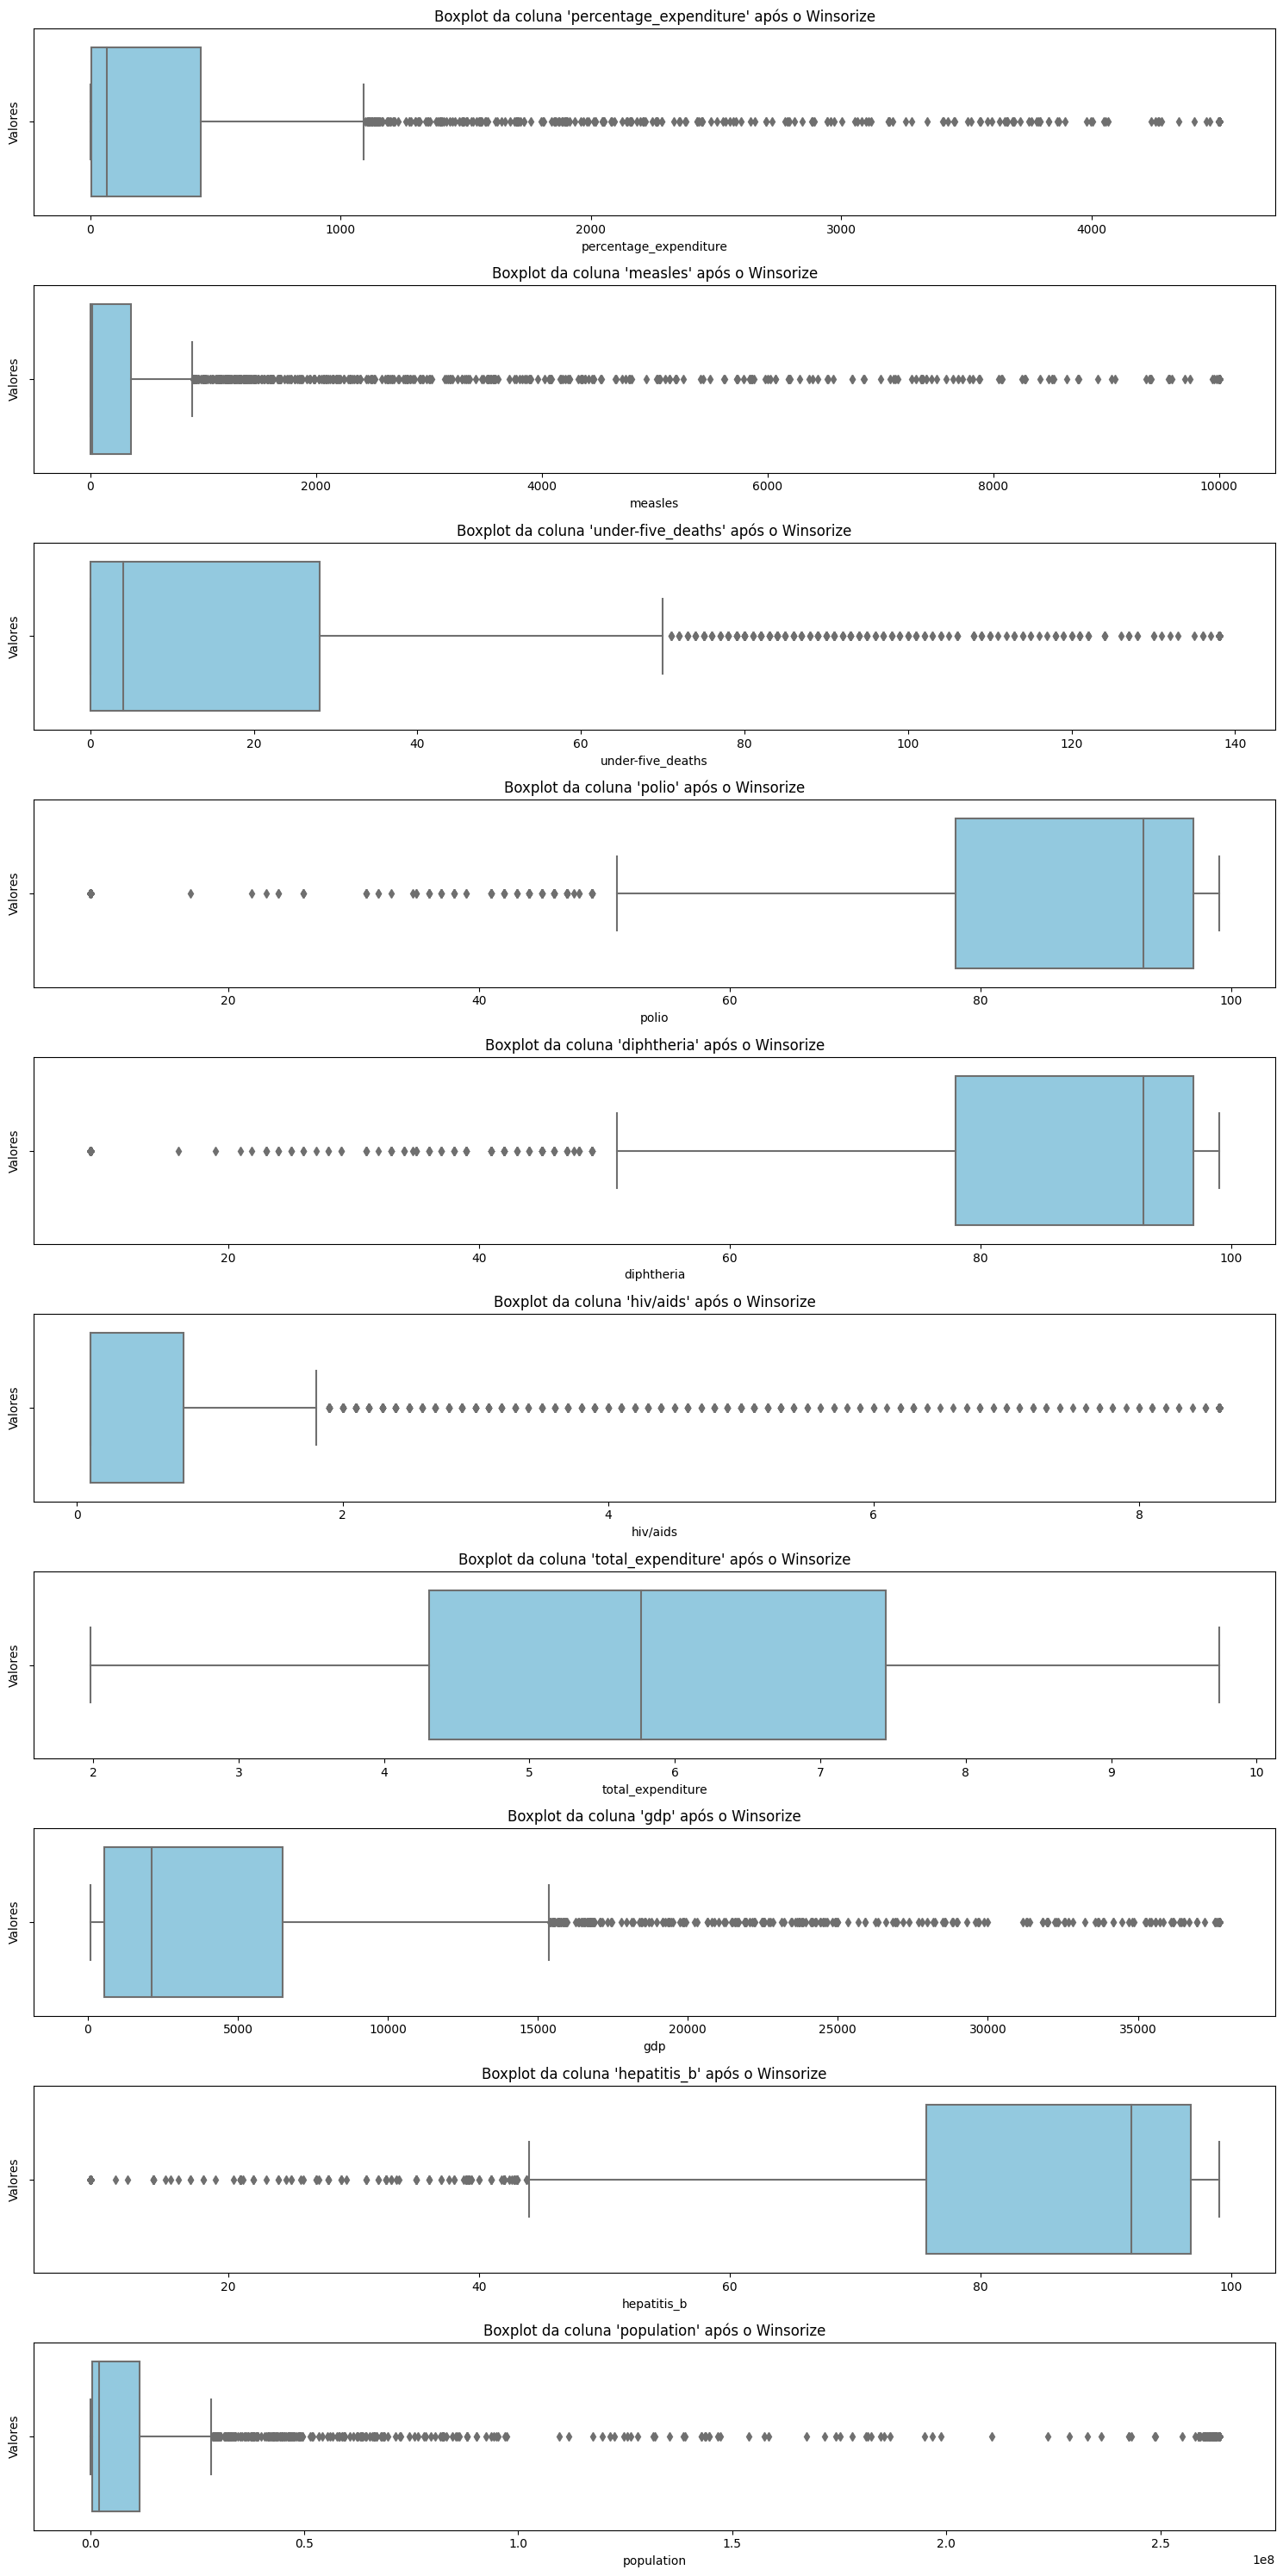

In [23]:
# Lista das colunas com distribuição não-normal ou platicúrtica
cols_with_outliers = ['percentage_expenditure', 'measles', 'under-five_deaths', 'polio', 'diphtheria', 'hiv/aids', 
                      'total_expenditure', 'gdp', 'hepatitis_b', 'population']

# Aplicar Winsorize nas colunas com outliers
for col in cols_with_outliers:
    df_final[col] = winsorize(df_final[col], limits=[0.05, 0.05])

# Plotar novamente os boxplots após o Winsorize (opcional para verificar o efeito do tratamento)
plt.figure(figsize=(15, 30))
for i, col in enumerate(cols_with_outliers):
    plt.subplot(len(cols_with_outliers), 1, i+1)
    sns.boxplot(x=df_final[col], color='skyblue')
    plt.title(f"Boxplot da coluna '{col}' após o Winsorize")
    plt.ylabel("Valores")
plt.tight_layout()
plt.show()

In [24]:
# Função para pré-processar os dados
def preprocess_data(df_final):
    # Excluindo as colunas "country" e "year"
    df_final = df_final.drop(columns=['country', 'year'])

    # Separar as features (X) e o target (y)
    X = df_final.drop(columns=['life_expectancy'])
    y = df_final['life_expectancy']

    # Aplicar one-hot encoding na coluna 'status'
    categorical_features = ['status']
    ct = ColumnTransformer([('onehot', OneHotEncoder(), categorical_features)], remainder='passthrough')
    X_encoded = ct.fit_transform(X)

    return X_encoded, y

# Features (X) e targets (y)
X, y = preprocess_data(df_final)

# Modelos
models = [
    ('LightGBM', LGBMRegressor(verbosity=0)),
    ('CatBoost', CatBoostRegressor(verbose=False)),
    ('Linear Regression', LinearRegression()),
    ('Random Forest', RandomForestRegressor()),
    ('XGBoost', XGBRegressor())
]

# Treinar e avaliar os modelos
print("Resultados da Avaliação dos Modelos:")
for model_name, model in models:
    # Dividir os dados em conjunto de treino e teste
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Treinar o modelo
    model.fit(X_train, y_train)

    # Predição
    y_pred = model.predict(X_test)

    # Calculando as métricas
    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = mean_squared_error(y_test, y_pred, squared=False)
    r2 = r2_score(y_test, y_pred)

    # Imprimir as métricas
    print(f"Modelo: {model_name}")
    print(f"Mean Squared Error (MSE): {mse}")
    print(f"Mean Absolute Error (MAE): {mae}")
    print(f"Root Mean Squared Error (RMSE): {rmse}")
    print(f"R-squared (R²): {r2}")
    print("\n")

Resultados da Avaliação dos Modelos:
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001085 seconds.
You can set `force_col_wise=true` to remove the overhead.
Modelo: LightGBM
Mean Squared Error (MSE): 2.930262294115101
Mean Absolute Error (MAE): 1.1525677767509686
Root Mean Squared Error (RMSE): 1.7118008920768504
R-squared (R²): 0.9662009169370769


Modelo: CatBoost
Mean Squared Error (MSE): 2.6965042686322165
Mean Absolute Error (MAE): 1.1474339669823292
Root Mean Squared Error (RMSE): 1.6421036108090794
R-squared (R²): 0.9688971966987174


Modelo: Linear Regression
Mean Squared Error (MSE): 12.83266958061276
Mean Absolute Error (MAE): 2.7210649311585304
Root Mean Squared Error (RMSE): 3.5822715671222864
R-squared (R²): 0.8519816925791082


Modelo: Random Forest
Mean Squared Error (MSE): 2.7614533256802702
Mean Absolute Error (MAE): 1.0835136054421766
Root Mean Squared Error (RMSE): 1.661762114648264
R-squared (R²): 0.9681480424068186


Mod

In [25]:
# Função para pré-processar os dados
def preprocess_data(df_final):
    # Excluindo as colunas "country" e "year"
    df_final = df_final.drop(columns=['country', 'year'])

    # Separar as features (X) e o target (y)
    X = df_final.drop(columns=['life_expectancy'])
    y = df_final['life_expectancy']

    # Aplicar one-hot encoding na coluna 'status'
    categorical_features = ['status']
    ct = ColumnTransformer([('onehot', OneHotEncoder(), categorical_features)], remainder='passthrough')
    X_encoded = ct.fit_transform(X)

    return X_encoded, y

# Features (X) e targets (y)
X, y = preprocess_data(df_final)

# Modelos
models = [
    ('LightGBM', LGBMRegressor(verbosity=0)),
    ('CatBoost', CatBoostRegressor(verbose=False)),
    ('Linear Regression', LinearRegression()),
    ('Random Forest', RandomForestRegressor()),
    ('XGBoost', XGBRegressor())
]

# Realizar a validação cruzada para cada modelo
print("Resultados da Avaliação dos Modelos com Validação Cruzada:")
for model_name, model in models:
    # Realizar a validação cruzada com 5 folds
    mse_scores = -cross_val_score(model, X, y, scoring='neg_mean_squared_error', cv=5)
    mean_mse = mse_scores.mean()

    # Calcular o RMSE usando o MSE
    rmse = np.sqrt(mean_mse)

    mae_scores = -cross_val_score(model, X, y, scoring='neg_mean_absolute_error', cv=5)
    mean_mae = mae_scores.mean()

    r2_scores = cross_val_score(model, X, y, scoring='r2', cv=5)
    mean_r2 = r2_scores.mean()

    print(f"Modelo: {model_name}")
    print(f"Mean Squared Error (MSE): {mean_mse}")
    print(f"Root Mean Squared Error (RMSE): {rmse}")
    print(f"Mean Absolute Error (MAE): {mean_mae}")
    print(f"R-squared (R²): {mean_r2}")
    print("\n")


Resultados da Avaliação dos Modelos com Validação Cruzada:
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001512 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000550 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000567 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000804 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000789 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000763 seconds.
You can s